In [1]:
import sys
sys.path.append('src')

from config import ExperimentConfig, save_result, load_results
from classical import classical_factor
from shor import shor_factor
from vqf_sim import factor_vqf_sim
from plots import *
from utils import *

import json
import numpy as np
import matplotlib.pyplot as plt

In [2]:
cfg_unknown = ExperimentConfig(
    shots=4096, n_restarts=3,
    maxiter_sim=500, maxiter_hw=150,
    s=2, mode='sim',
    backend_name=None, optimization_level=1
)
cfg_77 = ExperimentConfig(
    shots=4096, n_restarts=3,
    maxiter_sim=500, maxiter_hw=150,
    s=2, mode='sim',
    backend_name=None, optimization_level=1, 
    p=4, q=3
)
cfg_143 = ExperimentConfig(
    shots=4096, n_restarts=3,
    maxiter_sim=500, maxiter_hw=150,
    s=2, mode='sim',
    backend_name=None, optimization_level=1, 
    p=4, q=4
)
cfg_551 = ExperimentConfig(
    shots=4096, n_restarts=3,
    maxiter_sim=500, maxiter_hw=150,
    s=2, mode='sim',
    backend_name=None, optimization_level=1, 
    p=5, q=5
)
cfg_291311 = ExperimentConfig(
    shots=4096, n_restarts=3,
    maxiter_sim=500, maxiter_hw=150,
    s=2, mode='sim',
    backend_name=None, optimization_level=1, 
    p=557, q=523
)

In [3]:
N_tier1 = [35, 51, 77, 143, 551, 291311]

## Classical

In [4]:
for N in N_tier1:
    result = classical_factor(N)
    save_result(result, 'results/classical_results.json')
    print(f"N={N}: {result.factors}")

N=35: (5, 7)
N=51: (3, 17)
N=77: (7, 11)
N=143: (11, 13)
N=551: (19, 29)
N=291311: (523, 557)


## Shor

In [5]:
for N in N_tier1:
    try:
        print(f"N={N}")
        result, tr_circ, circ, _ = shor_factor(N, cfg_sim)
        save_result(result, 'results/shor_results.json')
        print(f"{result.factors} | depth: {result.circuit_depth}")
    except MemoryError:
        print(f"N={N}: MemoryError; skipped")
    except Exception as e:
        print(f"N={N}: Failed; {e}")

N=35
  attempt 1/10; picking a...
  a=23; building circuit...
  circuit built, running...
  counts received, processing...
(5, 7) | depth: 106197
N=51
  attempt 1/10; picking a...
  a=16; building circuit...
  circuit built, running...
  counts received, processing...
(3, 17) | depth: 8172
N=77
  attempt 1/10; picking a...
  a=16; building circuit...
  circuit built, running...
  counts received, processing...
  attempt 2/10; picking a...
  a=45; building circuit...
  circuit built, running...
  counts received, processing...
(11, 7) | depth: 498713
N=143
  attempt 1/10; picking a...
  a=95; building circuit...


KeyboardInterrupt: 

## VQF

### Preprocessing

In [5]:
from vqf_preprocessing import preprocess
from vqf_qubo import energy, qubit_list

for N in N_tier1:
    p, q, z, known, sub, clauses = preprocess(N)
    E = energy(clauses)
    qubits = qubit_list(E, p, q, known, sub)
    print(f"N={N}: {len(qubits)} qubits")

N=35: 1 qubits
N=51: 0 qubits
N=77: 3 qubits
N=143: 12 qubits
N=551: 20 qubits
N=291311: 61 qubits


### Simulation

#### Unknown factor bit-length

In [5]:
for N in N_tier1[:-1]:
    try:
        result, tr_circ, circ, params = factor_vqf_sim(N, cfg_unknown)
        save_result(result, 'results/vqf_sim_results.json')
        print(f"N={N}: success={result.success}, E_opt={result.E_opt}")
    except MemoryError:
        print(f"N={N}: MemoryError; skipped")
    except Exception as e:
        print(f"N={N}: Failed; {e}")

N=35: 1 qubits after preprocessing
N=35: success=True, E_opt=None
N=51: 0 qubits after preprocessing
N=51: success=True, E_opt=None
N=77: 3 qubits after preprocessing
  depth=20, params=4, gates=31
  p=1: E=0.3823
  p=2: E=0.2769

── Top 5 bitstrings (N=77) ──
  101: 1599/4096 → 11×7 valid=True
  011: 1593/4096 → 7×11 valid=True
  010: 301/4096 → 5×9 valid=False
  100: 257/4096 → 9×5 valid=False
  001: 117/4096 → 3×15 valid=False
N=77: success=True, E_opt=0.27685546875
N=143: 12 qubits after preprocessing
  depth=532, params=4, gates=815
  p=1: E=20.8059
  p=2: E=16.3489

── Top 5 bitstrings (N=143) ──
  100000100010: 13/4096 → 5×11 valid=False
  101011100100: 12/4096 → 9×15 valid=False
  101010011100: 11/4096 → 57×7 valid=False
  101010101010: 10/4096 → 21×11 valid=False
  001010011100: 10/4096 → 57×7 valid=False
N=143: success=True, E_opt=16.348876953125
N=551: 20 qubits after preprocessing
  depth=1373, params=4, gates=2471
  p=1: E=41.6782
  p=2: E=42.1775

── Top 5 bitstrings (N=5

#### Known bit-length runs

In [7]:
try:
    result, tr_circ, circ, params = factor_vqf_sim(77, cfg_77)
    save_result(result, 'results/vqf_sim_results.json')
    print(f"N=77: success={result.success}, E_opt={result.E_opt}")

    result, tr_circ, circ, params = factor_vqf_sim(143, cfg_143)
    save_result(result, 'results/vqf_sim_results.json')
    print(f"N=143: success={result.success}, E_opt={result.E_opt}")

    result, tr_circ, circ, params = factor_vqf_sim(551, cfg_551)
    save_result(result, 'results/vqf_sim_results.json')
    print(f"N=551: success={result.success}, E_opt={result.E_opt}")

except MemoryError:
    print(f"N={N}: MemoryError; skipped")
except Exception as e:
    print(f"N={N}: Failed; {e}")

N=77: 0 qubits after preprocessing
N=77: success=True, E_opt=None
N=143: 1 qubits after preprocessing
N=143: success=True, E_opt=None
N=551: 12 qubits after preprocessing
  depth=258, params=4, gates=465
  p=1: E=35.3376
  p=2: E=16.0234

── Top 5 bitstrings (N=551) ──
  100110101110: 20/4096 → 29×27 valid=False
  100110001011: 14/4096 → 23×25 valid=False
  010101101110: 13/4096 → 29×27 valid=False
  010101101001: 12/4096 → 19×29 valid=True
  100101000101: 12/4096 → 27×21 valid=False
N=551: success=True, E_opt=16.0234375


#### QAOA layer sweep

##### N=77

In [9]:
for s in [1, 2, 3, 4]:
    cfg_sweep = ExperimentConfig(
        shots=4096, n_restarts=3,
        maxiter_sim=500, s=s, mode='sim'
    )
    result, _, _, _ = factor_vqf_sim(77, cfg_sweep)
    save_result(result, 'results/vqf_layer_sweep.json')
    print(f"s={s}: success_prob={result.success_prob:.3f}, E_opt={result.E_opt:.4f}\n\n")

N=77: 3 qubits after preprocessing
  depth=11, params=2, gates=19
  p=1: E=0.3667

── Top 5 bitstrings (N=77) ──
  101: 1376/4096 → 11×7 valid=True
  011: 1329/4096 → 7×11 valid=True
  100: 453/4096 → 9×5 valid=False
  010: 432/4096 → 5×9 valid=False
  111: 212/4096 → 15×3 valid=False
s=1: success_prob=0.660, E_opt=0.3667


N=77: 3 qubits after preprocessing
  depth=20, params=4, gates=31
  p=1: E=0.3831
  p=2: E=0.2148

── Top 5 bitstrings (N=77) ──
  101: 1677/4096 → 11×7 valid=True
  011: 1611/4096 → 7×11 valid=True
  010: 226/4096 → 5×9 valid=False
  100: 213/4096 → 9×5 valid=False
  111: 167/4096 → 15×3 valid=False
s=2: success_prob=0.803, E_opt=0.2148


N=77: 3 qubits after preprocessing
  depth=29, params=6, gates=43
  p=1: E=0.3928
  p=2: E=0.2214
  p=3: E=0.2190

── Top 5 bitstrings (N=77) ──
  101: 1715/4096 → 11×7 valid=True
  011: 1671/4096 → 7×11 valid=True
  001: 227/4096 → 3×15 valid=False
  111: 227/4096 → 15×3 valid=False
  010: 95/4096 → 5×9 valid=False
s=3: success_p

#### N=143

In [11]:
for s in [1, 2, 3, 4]:
    cfg_sweep = ExperimentConfig(
        shots=4096, n_restarts=3,
        maxiter_sim=500, s=s, mode='sim'
    )
    result, _, _, _ = factor_vqf_sim(143, cfg_sweep)
    save_result(result, 'results/vqf_layer_sweep.json')
    print(f"s={s}: success_prob={result.success_prob:.3f}, E_opt={result.E_opt:.4f}")

N=143: 12 qubits after preprocessing
  depth=267, params=2, gates=420
  p=1: E=16.5322

── Top 5 bitstrings (N=143) ──
  010010010100: 10/4096 → 41×7 valid=False
  010011101010: 10/4096 → 21×11 valid=False
  110010011100: 9/4096 → 57×7 valid=False
  110010010100: 8/4096 → 41×7 valid=False
  000001110000: 7/4096 → 33×15 valid=False
s=1: success_prob=0.029, E_opt=16.5322
N=143: 12 qubits after preprocessing
  depth=532, params=4, gates=815
  p=1: E=20.4744
  p=2: E=17.2976

── Top 5 bitstrings (N=143) ──
  000000000110: 13/4096 → 13×3 valid=False
  100010000101: 11/4096 → 11×5 valid=False
  000000000100: 10/4096 → 9×7 valid=False
  100000110011: 10/4096 → 39×9 valid=False
  000000010010: 10/4096 → 37×3 valid=False
s=2: success_prob=0.035, E_opt=17.2976
N=143: 12 qubits after preprocessing
  depth=797, params=6, gates=1210
  p=1: E=15.3015
  p=2: E=14.0334
  p=3: E=15.4370

── Top 5 bitstrings (N=143) ──
  101101011110: 20/4096 → 61×3 valid=False
  010010111011: 20/4096 → 55×9 valid=False

## Results

In [4]:
classical = load_results('results/classical_results.json')
shor      = load_results('results/shor_results.json')
vqf_sim   = load_results('results/vqf_sim_results.json')

=== Mean Success Probabilities per N ===

[Category: width-unknown-vqf-sim]
  N = 77 -> 0.6956 (from 2 run(s))
  N = 143 -> 0.0309 (from 2 run(s))
  N = 551 -> 0.0034 (from 2 run(s))

[Category: width-known-vqf-sim]
  N = 551 -> 0.1320 (from 2 run(s))
=== Best Success Probabilities per N ===

[Category: width-unknown-vqf-sim]
  N = 77 -> 0.779296875
  N = 143 -> 0.035400390625
  N = 551 -> 0.003662109375

[Category: width-known-vqf-sim]
  N = 551 -> 0.134521484375


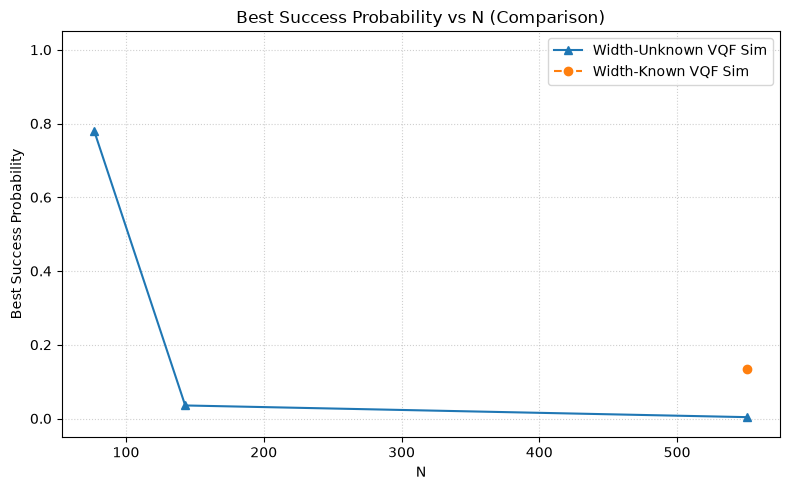

In [10]:
#VQF success prob vs. N
vqf_sim   = load_results('results/vqf_sim_results.json')

mean = get_mean_success_prob(vqf_sim)
best = get_best_success_prob(vqf_sim)
plot_best_success_prob(best)

=== Best Success Probabilities per N ===

[Category: width-unknown-vqf-sim]
  N = 77 -> 0.779296875
  N = 143 -> 0.035400390625
  N = 551 -> 0.003662109375

[Category: width-known-vqf-sim]
  N = 551 -> 0.134521484375
=== Width-Known VQF Sim: Best Success Probabilities per N ===
  N = 551 -> 0.1345
=== Width-Known VQF Sim: Mean Success Probabilities per N ===
  N = 551 -> 0.1320 (from 2 run(s))


TypeError: float() argument must be a string or a real number, not 'dict'

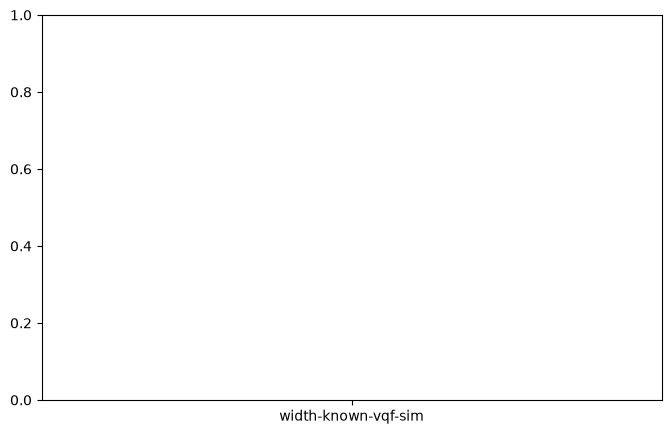

In [6]:
vqf_sim   = load_results('results/vqf_sim_results.json')

best_unknown = get_best_success_prob(vqf_sim)

best_known = get_width_known_best_success_prob(vqf_sim)
mean_unknown = get_width_known_mean_success_prob(vqf_sim)
plot_comparison_best_prob(best_unknown, best_known)

=== Layer Sweep: Best Success Probabilities per N per QAOA layer ===

1 layer(s)
  N = 77 -> 0.6826171875
  N = 143 -> 0.034423828125

2 layer(s)
  N = 77 -> 0.813232421875
  N = 143 -> 0.037841796875

3 layer(s)
  N = 77 -> 0.82666015625
  N = 143 -> 0.064697265625

4 layer(s)
  N = 77 -> 0.863525390625
  N = 143 -> 0.03955078125
=== Layer Sweep: Mean Success Probabilities per N per QAOA Layer ===

1 layer(s)
  N = 77 -> 0.6715 (from 2 run(s))
  N = 143 -> 0.0319 (from 2 run(s))

2 layer(s)
  N = 77 -> 0.8080 (from 2 run(s))
  N = 143 -> 0.0366 (from 2 run(s))

3 layer(s)
  N = 77 -> 0.7793 (from 2 run(s))
  N = 143 -> 0.0529 (from 2 run(s))

4 layer(s)
  N = 77 -> 0.8604 (from 2 run(s))
  N = 143 -> 0.0363 (from 2 run(s))


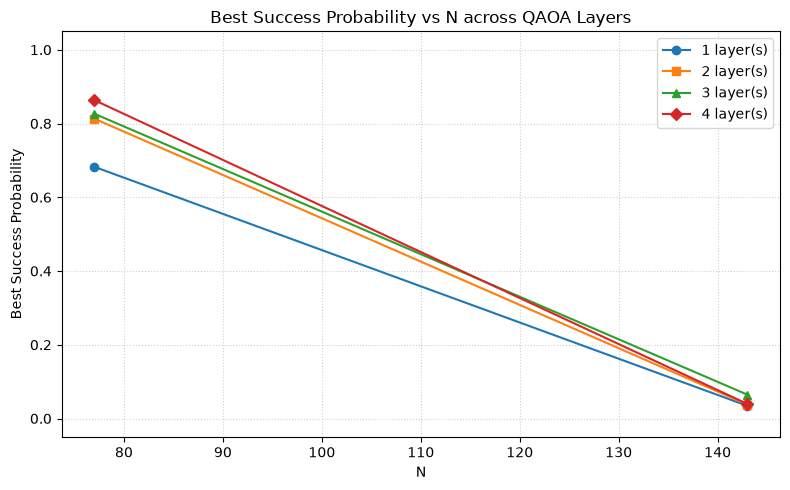

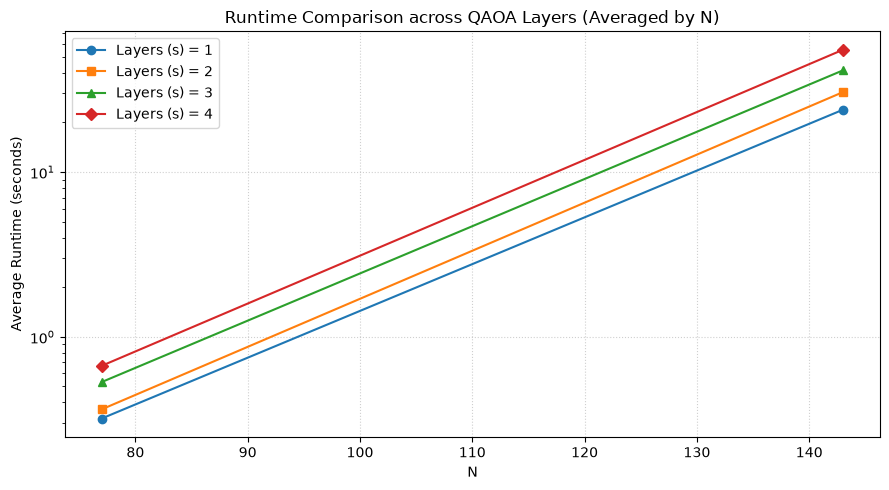

In [6]:
vqf_sweep = load_results('results/vqf_layer_sweep.json')

best_sweep = get_layer_sweep_best_success_prob(vqf_sweep)
mean_sweep = get_layer_sweep_mean_success_prob(vqf_sweep)

plot_layer_sweep_best_success_prob(best_sweep)
plot_layer_sweep_runtimes(vqf_sweep)

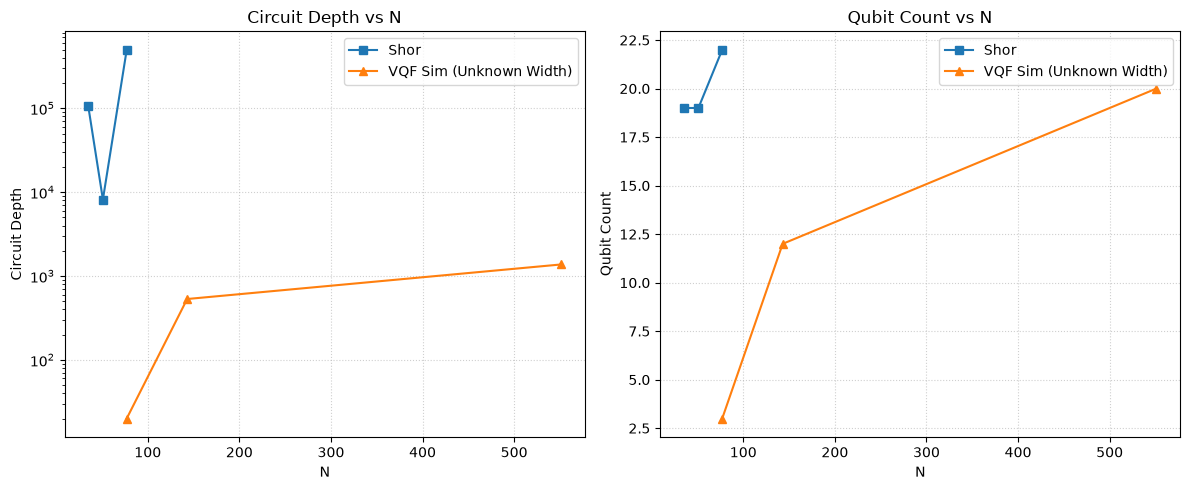

In [5]:
#Shor+VQF
shor      = load_results('results/shor_results.json')
vqf_sim   = load_results('results/vqf_sim_results.json')

plot_circuit_metrics(shor, vqf_sim)

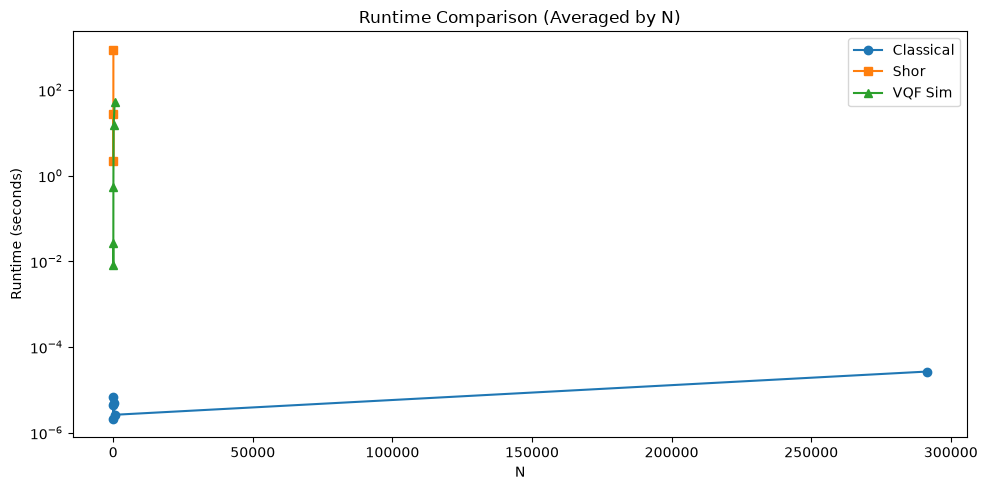

In [6]:
# Runtime Classical+Shor+VQF
classical = load_results('results/classical_results.json')
shor      = load_results('results/shor_results.json')
vqf_sim   = load_results('results/vqf_sim_results.json')

plot_runtime(classical, shor, vqf_sim)

## Circuit Diagrams

N=77: 3 qubits after preprocessing
  depth=20, params=4, gates=31
  p=1: E=0.3796
  p=2: E=0.1316

── Top 5 bitstrings (N=77) ──
  011: 1767/4096 → 7×11 valid=True
  101: 1761/4096 → 11×7 valid=True
  111: 184/4096 → 15×3 valid=False
  001: 172/4096 → 3×15 valid=False
  100: 110/4096 → 9×5 valid=False


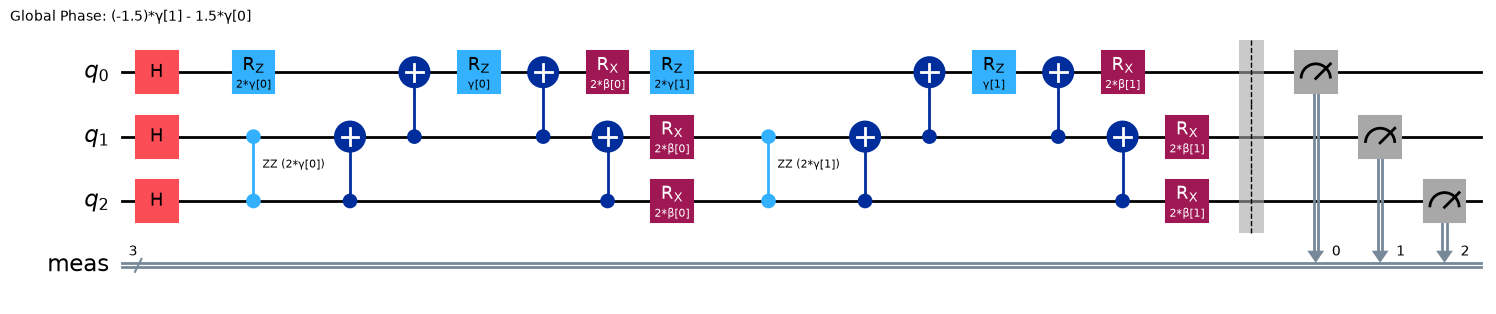

In [9]:
# Print (& save) the circuits
result, tr_circ, circ, params = factor_vqf_sim(77, cfg_unknown)
circ.draw(output='mpl', filename='figures/vqf_sim_77.png')